<a href="https://colab.research.google.com/github/Anasss004/Tp_mlp_bean/blob/main/TP_MLP_DryBean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP — Construire et entraîner un MLP avec TensorFlow/Keras
## Dataset : Dry Bean (haricots secs)

**But :** prédire la **variété** d'un haricot (7 classes) à partir de **16 mesures** (aire, périmètre, axes, etc.).

**Plan du TP :** données → séparation → modèle → compile → fit → courbes → évaluation → comparaisons → régularisation → arrêt précoce → sauvegarde.


## 0. Préparation de l'environnement
On installe `ucimlrepo` (pour télécharger le dataset) puis on importe les bibliothèques.
Le **seed** fixe le hasard pour obtenir des résultats reproductibles.

In [ ]:
!pip install ucimlrepo -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow :", tf.__version__, "Keras :", getattr(keras, "__version__", "incluse dans TensorFlow"))
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

TensorFlow : 2.21.0 Keras : 3.13.2


## Lecture d'un petit MLP NumPy (XNOR) : ce qui se passe à l'intérieur
Ce code est **fourni** : il suffit de l'exécuter et de le lire. Il montre les 4 étapes de tout apprentissage :

1. **Propagation avant** (`forward`) : les entrées traversent les couches et donnent une prédiction.
2. **Perte** : on mesure l'erreur entre la prédiction et la cible.
3. **Rétropropagation** : on calcule comment corriger chaque poids (les gradients).
4. **Mise à jour** : on modifie poids et biais (`W -= rate * dW`).

Avec Keras, `fit` fait tout cela automatiquement.

x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


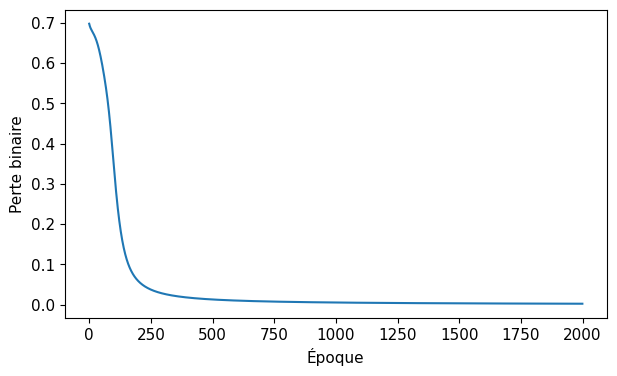

In [ ]:
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))
        self.b1 = np.zeros((1, 3))
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))
        self.b2 = np.zeros((1, 1))

    def forward(self, X):
        # ÉTAPE 1 : propagation avant
        H = np.tanh(X @ self.W1 + self.b1)
        Z = H @ self.W2 + self.b2
        P = np.exp(-np.logaddexp(0, -Z))  # sigmoïde stable
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)
            # ÉTAPE 2 : mesure de l'erreur par la perte
            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))
            # ÉTAPE 3 : rétropropagation
            D2 = (P-y)/len(y)
            dW2 = H.T @ D2
            db2 = D2.sum(axis=0, keepdims=True)
            D1 = (D2 @ self.W2.T) * (1-H**2)
            dW1 = X.T @ D1
            db1 = D1.sum(axis=0, keepdims=True)
            # ÉTAPE 4 : mise à jour des paramètres
            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_logic = np.array([[1.],[0.],[0.],[1.]])
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()
logic_loss = mini.fit(X_logic, y_logic)
final_prob = mini.forward(X_logic)[2]
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))

## 1. Charger et comprendre les données
- `X` : les **16 mesures** de chaque haricot (une ligne = un haricot).
- `y` : la **variété** (texte). Keras a besoin de nombres, donc on l'encode avec `LabelEncoder` (0 à 6).



In [ ]:
from ucimlrepo import fetch_ucirepo

dry_bean = fetch_ucirepo(id=602)
X_df = dry_bean.data.features
y_txt = dry_bean.data.targets.values.ravel()

print(X_df.shape)
print(y_txt.shape)

(13611, 16)
(13611,)


Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
dtype: object

Valeurs manquantes : 0
Doublons exacts : 68

Effectifs par variété :
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


,mean,std,min,max
Area,53048.284549,29324.095717,20420.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,738.860154
MinorAxisLength,202.270714,44.970091,122.512653,460.198497
AspectRatio,1.583242,0.246678,1.024868,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,569.374358
Extent,0.749733,0.049086,0.555315,0.866195
Solidity,0.987143,0.004660,0.919246,0.994677


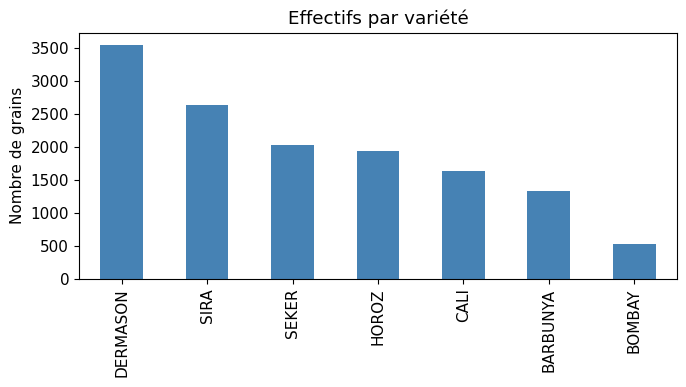

In [ ]:
# Exploration rapide
print(X_df.dtypes)
print("\nValeurs manquantes :", int(X_df.isna().sum().sum()))
print("Doublons exacts :", int(X_df.duplicated().sum()))
print("\nEffectifs par variété :")
print(pd.Series(y_txt).value_counts())
display(X_df.describe().T[["mean", "std", "min", "max"]])

pd.Series(y_txt).value_counts().plot(kind="bar", color="steelblue")
plt.title("Effectifs par variété")
plt.ylabel("Nombre de grains")
plt.tight_layout()
plt.show()

In [ ]:
# Conversion pour Keras : tableau NumPy float32 + cibles entières
X = X_df.values.astype("float32")

le = LabelEncoder()
y = le.fit_transform(y_txt)          # texte -> entiers 0 à 6
print("Correspondance :", dict(zip(le.classes_, range(len(le.classes_)))))
print("X :", X.shape, "y :", y.shape)

Correspondance : {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}
X : (13611, 16) y : (13611,)


## 2. Séparer et préparer les données
On découpe en **60 % train / 20 % validation / 20 % test** :
- **train** : le modèle apprend dessus ;
- **validation** : on compare les réglages ;
- **test** : évaluation finale, à ne pas utiliser pour choisir.

`stratify` garde les mêmes proportions de classes. Le `StandardScaler` (centrer-réduire) est **ajusté sur le train seulement** pour éviter la fuite d'information.



In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # apprend moyenne/écart-type ET transforme
X_val_s = scaler.transform(X_val)           # réutilise les mêmes statistiques
X_test_s = scaler.transform(X_test)

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-3)

Train / validation / test : 8166 2722 2723


## 3. Définir le MLP avec `Sequential` et `Dense`
Architecture **16 → 32 → 7** :
- `Input(shape=(16,))` : une observation = 16 nombres ;
- `Dense(32, activation="relu")` : 32 neurones cachés ;
- `Dense(7, activation="softmax")` : 7 probabilités (une par variété, somme = 1).

Paramètres : (16×32 + 32) + (32×7 + 7) = 544 + 231 = **775**.



In [ ]:
model = keras.Sequential([
    keras.Input(shape=(16,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(7, activation="softmax"),
])
model.summary()
print("Paramètres :", model.count_params())
assert model.count_params() == 775

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


## 4. Configurer l'apprentissage avec `compile`
On choisit :
- **optimizer** : Adam (taux 0,001), l'algorithme qui corrige les poids ;
- **loss** : `SparseCategoricalCrossentropy`, la perte à minimiser (« sparse » = cibles entières, pas one-hot) ;
- **metrics** : accuracy, pour juger les résultats.


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

## 5. Entraîner avec `fit`
`fit` fait tout automatiquement : prédiction, perte, gradients, mise à jour.
- `epochs=40` : 40 passages complets sur le train ;
- `batch_size=32` : une mise à jour des poids tous les 32 exemples ;
- `validation_data` : mesure la performance à chaque époque, **sans modifier les poids**.



In [ ]:
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=40,
    batch_size=32,
    verbose=0,
)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))

Courbes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40


## 6. Lire les courbes d'apprentissage
On compare **train** et **validation** : si la perte train baisse mais que celle de validation remonte, c'est du **surapprentissage**.



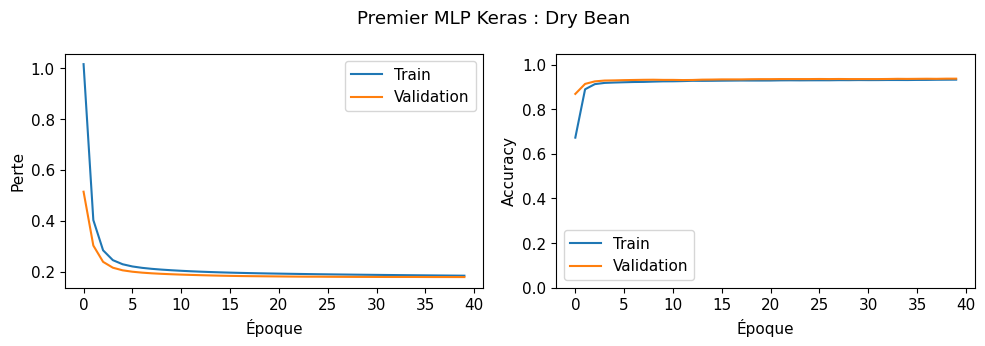

In [ ]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP Keras : Dry Bean")

## 7. Prédire et évaluer sur validation
- `evaluate` : perte et métriques ;
- `predict` : 7 probabilités par haricot ;
- `argmax` : la classe prédite = la plus grande probabilité.

La **matrice de confusion** : lignes = classe réelle, colonnes = classe prédite. La diagonale = bonnes réponses.


Évaluation : {'accuracy': 0.9371785521507263, 'loss': 0.1784835010766983}
Probabilités : (2722, 7)
              precision    recall  f1-score   support

    BARBUNYA      0.935     0.924     0.930       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.933     0.933     0.933       326
    DERMASON      0.927     0.944     0.935       709
       HOROZ      0.959     0.959     0.959       386
       SEKER      0.980     0.963     0.971       405
        SIRA      0.895     0.890     0.892       527

    accuracy                          0.937      2722
   macro avg      0.947     0.945     0.946      2722
weighted avg      0.937     0.937     0.937      2722



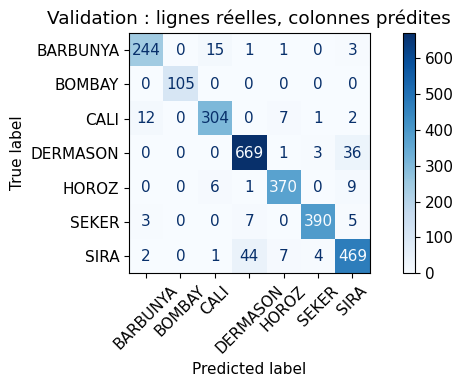

In [ ]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = np.argmax(prob_val, axis=1)

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)
print(classification_report(y_val, pred_val, target_names=le.classes_,
                            digits=3, zero_division=0))
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(7))
ConfusionMatrixDisplay(cm_val, display_labels=le.classes_).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.tight_layout()
plt.show()

## 8. Comparer des réglages avec des modèles neufs
`create_model` fabrique un modèle Keras neuf à chaque appel (même seed → mêmes poids de départ), ce qui évite de recopier `Sequential` et `compile`.
`summarize` résume un modèle sur la validation (paramètres, époques, perte CE sans pénalité, accuracy, F1 macro).

> Le **F1 macro** donne le même poids à chaque classe : il est plus honnête que l'accuracy quand les classes sont déséquilibrées.

In [ ]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=16, n_classes=7):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()
def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}

### 8.1 Taux d'apprentissage
On entraîne un modèle neuf avec trois taux : 0,0001 (très petit), 0,001 (standard), 0,05 (grand).



{'modèle': 'Adam, taux=0.0001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22442062199115753, 'accuracy_validation': 0.9268919911829537, 'F1_macro_validation': 0.937991888557919}
{'modèle': 'Adam, taux=0.001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'Adam, taux=0.05', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22222593426704407, 'accuracy_validation': 0.9287288758265981, 'F1_macro_validation': 0.9378875194399644}


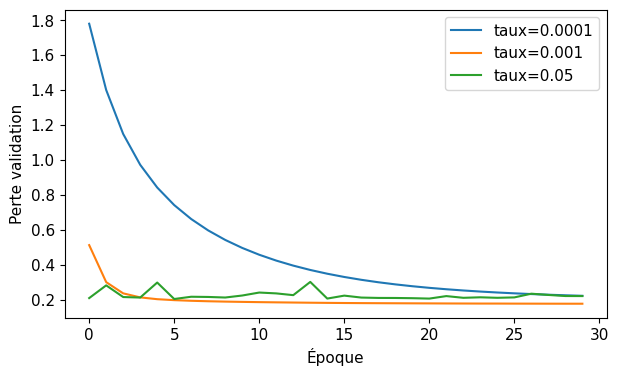

In [ ]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

### 8.2 Optimisateurs : Adam vs SGD
Un seul argument change : `optimizer=`. Adam adapte le pas de chaque paramètre ; SGD (sans momentum) applique le même taux partout.



In [ ]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'sgd', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.45739132165908813, 'accuracy_validation': 0.8986039676708303, 'F1_macro_validation': 0.9127455166665006}


### 8.3 Tailles de lots
Un exemple (lot=1), un mini-lot (32), le lot complet. Nombre de mises à jour par époque = `ceil(n_train / taille)`.





In [ ]:
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.18420544266700745, 'accuracy_validation': 0.9338721528288023, 'F1_macro_validation': 0.9435933096670807}
Mises à jour par époque : 8166
{'modèle': 'SGD, lot=32', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.24625104665756226, 'accuracy_validation': 0.9261572373254959, 'F1_macro_validation': 0.9373532043967572}
Mises à jour par époque : 256
{'modèle': 'SGD, lot=8166', 'paramètres': 775, 'époques': 10, 'CE_validation': 2.153029680252075, 'accuracy_validation': 0.022777369581190303, 'F1_macro_validation': 0.01857896525460564}
Mises à jour par époque : 1


### 8.4 Couches cachées et activations
On compare un réseau étroit (2 neurones), la référence (32), deux couches (64 puis 32) et une activation `tanh`.


In [ ]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"), ("référence", (32,), "relu"),
        ("deux couches", (64, 32), "relu"), ("tanh", (32,), "tanh")]:
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 55, 'époques': 30, 'CE_validation': 0.34601786732673645, 'accuracy_validation': 0.9103600293901543, 'F1_macro_validation': 0.9161530629832253}
{'modèle': 'référence', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'deux couches', 'paramètres': 3399, 'époques': 30, 'CE_validation': 0.18276962637901306, 'accuracy_validation': 0.9382806759735489, 'F1_macro_validation': 0.9466792370174787}
{'modèle': 'tanh', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.18017995357513428, 'accuracy_validation': 0.934974283614989, 'F1_macro_validation': 0.9438026846955491}


## 9. Régulariser (lutter contre le surapprentissage)
Une option à la fois, sur un MLP à deux couches cachées :
- **L1 / L2** : pénalisent les poids trop grands ;
- **Dropout** : éteint des neurones au hasard **pendant l'entraînement seulement** ;
- **BatchNorm** : normalise les activations à l'intérieur du réseau (ne remplace pas le `StandardScaler`).



{'modèle': 'référence', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.18359825015068054, 'accuracy_validation': 0.93791329904482, 'F1_macro_validation': 0.9469339596168754}
Perte evaluate, pénalité éventuelle incluse : 0.18359807133674622
{'modèle': 'L1', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17847295105457306, 'accuracy_validation': 0.9390154298310066, 'F1_macro_validation': 0.9476335223050648}
Perte evaluate, pénalité éventuelle incluse : 0.21005816757678986
{'modèle': 'L2', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17877866327762604, 'accuracy_validation': 0.9364437913299045, 'F1_macro_validation': 0.9457788528996175}
Perte evaluate, pénalité éventuelle incluse : 0.20822863280773163
{'modèle': 'Dropout', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.1787683069705963, 'accuracy_validation': 0.9375459221160911, 'F1_macro_validation': 0.9465067102998835}
Perte evaluate, pénalité éventuelle incluse : 0.1787680983543396
{'modèle': 'BatchNorm', 

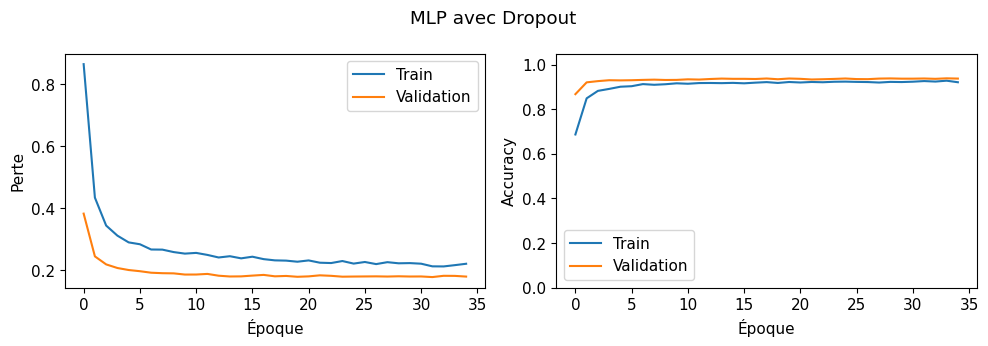

In [ ]:
regularization_runs = {}
configs = [
    ("référence", {}),
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),
    ("Dropout", {"dropout": 0.25}),
    ("BatchNorm", {"batchnorm": True})
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    print("Perte evaluate, pénalité éventuelle incluse :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

**Diagnostic Dropout :** en mode évaluation (`training=False`) la sortie est stable ; en mode entraînement (`training=True`) elle change à chaque appel.

In [ ]:
probe = keras.Sequential([
    keras.Input(shape=(16,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(7, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))
print("Entraînement identique :", np.allclose(train1, train2))

Évaluation identique : True
Entraînement identique : False


## 10. Arrêt précoce avec `EarlyStopping`
On autorise jusqu'à 100 époques, mais on s'arrête quand la perte de validation ne s'améliore plus pendant 8 époques (`patience=8`). `restore_best_weights=True` remet les **meilleurs poids**, pas ceux de la dernière époque.



Époques exécutées : 74
Meilleure époque : 66
{'accuracy': 0.9360764026641846, 'loss': 0.1774529367685318}


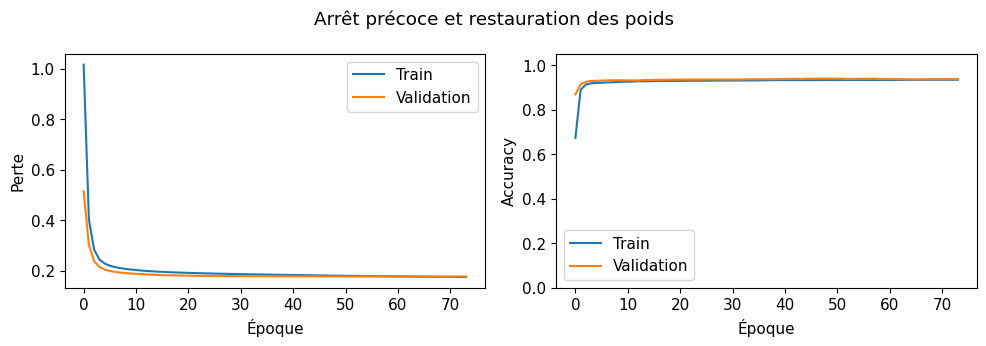

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    min_delta=0,
    restore_best_weights=True,
)
early_model = create_model()
early_history = early_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0,
)

print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

## 11. Sauvegarder et recharger le modèle
Le fichier `.keras` contient l'architecture et les poids, **mais pas le `StandardScaler` ni le `LabelEncoder`**. On les sauvegarde séparément avec `joblib`.



In [ ]:
import joblib

early_model.save("modele_drybean.keras")
loaded_model = keras.models.load_model("modele_drybean.keras")
joblib.dump(scaler, "scaler_drybean.joblib")
joblib.dump(le, "label_encoder_drybean.joblib")

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

Prédictions conservées : True


**Utilisation dans une application :** nouvelles mesures brutes → même scaler (`transform` uniquement) → `predict` → `argmax` → `le.inverse_transform` pour le nom de la variété.

In [ ]:
nouvelle_mesure = X[:3]                              # 3 haricots bruts (exemple)
x_s = scaler.transform(nouvelle_mesure)              # PAS de fit : on réutilise le scaler
classes = loaded_model.predict(x_s, verbose=0).argmax(axis=1)
print("Variétés prédites :", le.inverse_transform(classes))
print("Variétés réelles  :", le.inverse_transform(y[:3]))

Variétés prédites : ['SEKER' 'SEKER' 'SEKER']
Variétés réelles  : ['SEKER' 'SEKER' 'SEKER']


In [ ]:
# Télécharger les fichiers sur votre ordinateur (Colab uniquement)
try:
    from google.colab import files
    files.download("modele_drybean.keras")
    files.download("scaler_drybean.joblib")
    files.download("label_encoder_drybean.joblib")
except ImportError:
    print("Hors Colab : les fichiers sont dans le dossier courant.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. (Facultatif) Évaluation finale sur le test
À faire **une seule fois**, après avoir choisi le modèle sur la validation, **sans retoucher les réglages** ensuite.

Accuracy test : 0.9221446933529196
F1 macro test : 0.9332429984596422
              precision    recall  f1-score   support

    BARBUNYA      0.937     0.902     0.919       265
      BOMBAY      1.000     0.990     0.995       104
        CALI      0.925     0.945     0.935       326
    DERMASON      0.915     0.921     0.918       709
       HOROZ      0.961     0.946     0.953       386
       SEKER      0.944     0.951     0.947       406
        SIRA      0.864     0.867     0.866       527

    accuracy                          0.922      2723
   macro avg      0.935     0.932     0.933      2723
weighted avg      0.922     0.922     0.922      2723



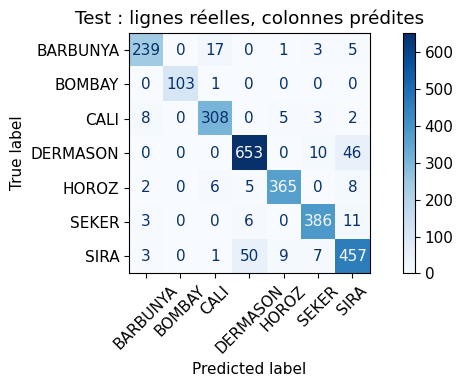

In [ ]:
best = early_model   # remplacer par le modèle choisi sur la validation
pred_test = best.predict(X_test_s, verbose=0).argmax(axis=1)
print("Accuracy test :", accuracy_score(y_test, pred_test))
print("F1 macro test :", f1_score(y_test, pred_test, average="macro"))
print(classification_report(y_test, pred_test, target_names=le.classes_, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=le.classes_).plot(cmap="Blues", xticks_rotation=45)
plt.title("Test : lignes réelles, colonnes prédites")
plt.tight_layout()
plt.show()

## Documentation utile
- [Sequential et Dense](https://keras.io/guides/sequential_model/)
- [compile, fit, evaluate, predict](https://keras.io/guides/training_with_built_in_methods/)
- [EarlyStopping](https://keras.io/api/callbacks/early_stopping/)
- [Dropout](https://keras.io/api/layers/regularization_layers/dropout/)
- [BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)
- Dataset : [Dry Bean (UCI)](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)